extends ["interpreting gpt: the logit lens"](https://www.lesswrong.com/posts/AcKRB8wDpdaN6v6ru/interpreting-gpt-the-logit-lens) with logit lens plots for other autoregressive LMs, like the **GPT-Neo** models from [EleutherAI](eleuther.ai).

models covered:

- **small models**
  - gpt2 125M
  - gpt-neo 125M
- **"gpt2-scale" models**
  - gpt2 1.5B
  - gpt-neo 1.3B
  - CTRL
- **larger models**
  - gpt-neo 2.7B

the original "logit lens" material is also extended here by:

- breaking down transformer blocks into their attn and mlp parts
- exploring different definitions of the "decoder"

----

interestingly, **gpt-neo** models do _not_ display the "logit lens" phenomenon like gpt2 does.

further investigation reveals that we can see similar behavior with gpt-neo **if** we tweak the original "lens" so the _final block_ of the model is counted as part of the "decoder" rather than part of the model.

**CTRL** _does_ display the "logit lens" phenomenon.  unlike gpt2, it not only "looks like the output" in late layers, it also "looks like the input" in early layers.

i don't know why the models differ like this.  i'm pretty sure it's not a bug, or some trivial quirk of how the models are represented in code.  some possibilities:

- different data
- different training schedule (~1 epoch vs many)
- different sized context window?  note CTRL has the smallest window here, neo the biggest

\- nostalgebraist, 5/10/21

CHANGELOG

- 5/11/21: added ctrl
- 5/17/21: updated with subblocks, decoder extensions, new plotting code

## environment setup

the next cell install finetuneanon's branch of `transformers` with modifications from [this PR](https://github.com/huggingface/transformers/pull/11630).

this is a change to the gpt-neo implementation that doesn't affect functionality, but will make some things much easier for us here.

`transformer-utils` is a package i wrote!

see the source at https://github.com/nostalgebraist/transformer-utils/

checks the GPU.

if it isn't a T4, P100, or V100, it's probably too small and you should try again later.

## code setup

ValueError: The number of FixedLocator locations (10), usually from a call to set_ticks, does not match the number of labels (9).

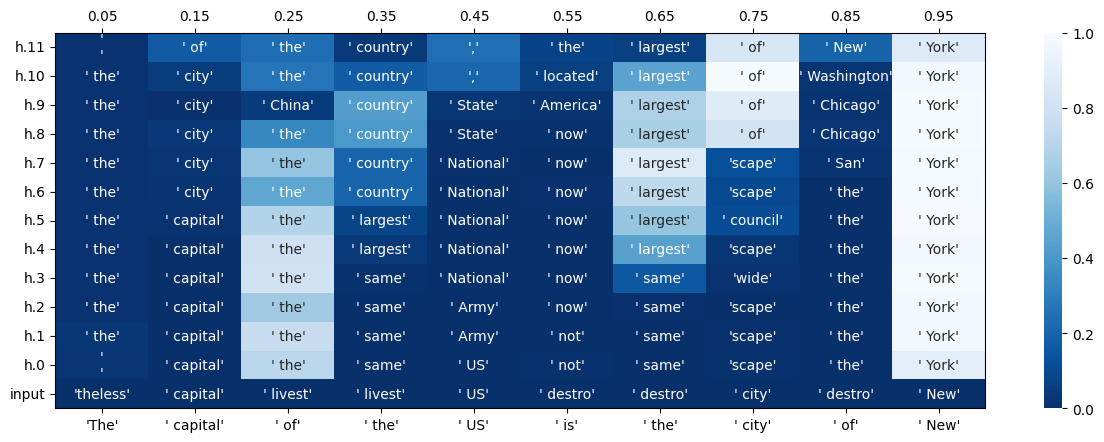

In [ ]:
import os
from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import login
import torch
from transformer_utils.logit_lens import plot_logit_lens
import gc

os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # Set to the GPU device you want to use

# Get Hugging Face token from environment variable
hf_token = os.getenv("HF_TOKEN")
if not hf_token:
    raise ValueError("HF_TOKEN environment variable not found")

# Log in to Hugging Face using the token
login(token=hf_token)

# Load the GPT-2 tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2")
model = model.cuda()


def cleanup_model(model):
    try:
      if hasattr(model, 'base_model_prefix') and len(model.base_model_prefix) > 0:
        bm = getattr(model, model.base_model_prefix)
        del bm
    except:
      pass
    del model

    gc.collect()
    torch.cuda.empty_cache()
    
sample_prompt = """The capital of the US is the city of New York"""


def text_to_input_ids(text):
    token_ids = tokenizer.encode(text, return_tensors="pt")  # returns a 1×N tensor on CPU
    return token_ids.cuda()

input_ids = text_to_input_ids(sample_prompt)

input_ids = input_ids[:, :10]


plot_logit_lens(model, tokenizer, input_ids, start_ix=0, end_ix=10, probs=True)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


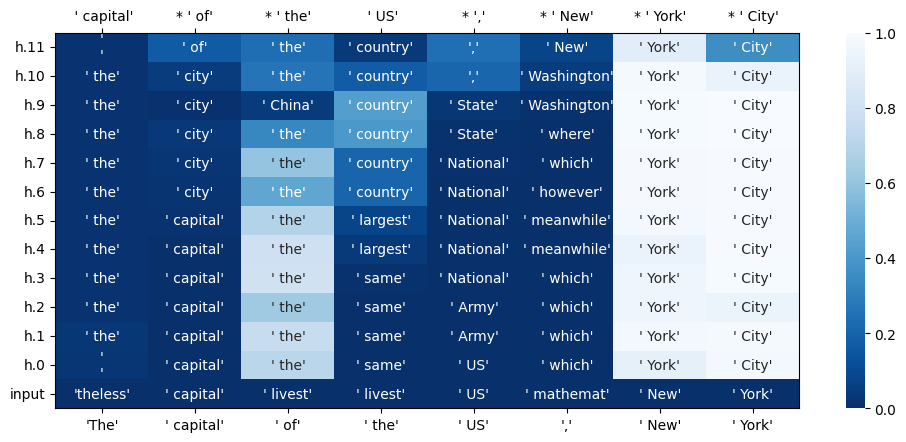

In [ ]:
import os
import gc
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import login
from transformer_utils.logit_lens import plot_logit_lens

# — If you want to force using a particular physical GPU, you can set:
# os.environ["CUDA_VISIBLE_DEVICES"] = "1"
# Then torch.cuda:0 will map to the GPU with index 1 on your machine.

# Hugging Face login token (you can also set HF_TOKEN as an env var instead)
hf_token = os.getenv("HF_TOKEN")
if not hf_token:
    raise ValueError("HF_TOKEN environment variable not found")
login(token=hf_token)

# Load GPT-2 onto GPU
tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2").cuda()

def cleanup_model(m):
    """Free up GPU memory when you’re done."""
    try:
        if hasattr(m, 'base_model_prefix') and len(m.base_model_prefix) > 0:
            bm = getattr(m, m.base_model_prefix)
            del bm
    except:
        pass
    del m
    gc.collect()
    torch.cuda.empty_cache()

# Our prompt
prompt = "The capital of the US"

# Tokenize on CPU, then immediately move to GPU
inputs = tokenizer(prompt, return_tensors="pt")       # shape = (1, prompt_len) on CPU
input_ids_gpu = inputs["input_ids"].cuda()             # now on cuda:0

# Greedy‐decode exactly 4 new tokens on GPU
outputs = model.generate(
    input_ids_gpu,      # (1, prompt_len) on cuda:0
    max_new_tokens=4,
    do_sample=False
)

# The full token‐ID sequence (prompt + 4 new tokens), on GPU
full_sequence = outputs                   # shape = (1, N + 4) on cuda:0

# Compute indices for plotting
start_ix = 0
end_ix = full_sequence.shape[1] - 1

# Plot on GPU (plot_logit_lens will pull logits internally, but the inputs are on cuda)
plot_logit_lens(
    model,
    tokenizer,
    full_sequence,    # already on cuda:0
    start_ix=start_ix,
    end_ix=end_ix,
    probs=True
)

# (Optional) free GPU memory
cleanup_model(model)


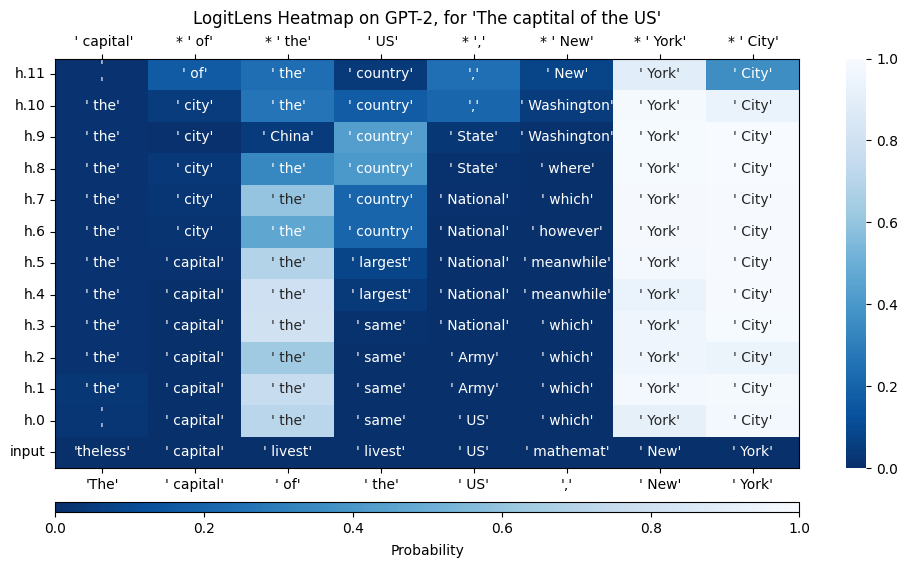

In [29]:
import matplotlib.pyplot as plt
from matplotlib.collections import QuadMesh

# 1. Your normal call
plot_logit_lens(model, tokenizer, full_sequence, start_ix=0, end_ix=end_ix, probs=True)

# 2. Locate the heat-map Axes and its QuadMesh
fig = plt.gcf()
heatmap_ax = next(
    ax for ax in fig.axes if any(isinstance(coll, QuadMesh) for coll in ax.collections)
)
quad = next(coll for coll in heatmap_ax.collections if isinstance(coll, QuadMesh))

# 3. Delete every *other* axes → this drops the original right-hand colour-bar
#for ax in fig.axes[:]:
#    if ax is not heatmap_ax:
#        fig.delaxes(ax)

# 4. Push the title higher
heatmap_ax.set_title("LogitLens Heatmap on GPT-2, for 'The captital of the US'", pad=25)   # pad is in points

# 5. Add a new horizontal colour-bar **manually** so we can control exact placement
#    ── grab the heat-map’s bounding box in figure-relative coords
box = heatmap_ax.get_position()
cbar_height = 0.02          # fraction of total figure height
gap        = 0.10           # vertical gap between heat-map and bar

cbar_ax = fig.add_axes([
    box.x0,                 # left stays the same
    box.y0 - gap - cbar_height,
    box.width,              # same width as heat-map
    cbar_height
])
cbar = fig.colorbar(quad, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Probability", labelpad=6)

# 6. Give the figure a bit of breathing room
fig.subplots_adjust(top=0.92, bottom=0.08)

plt.show()


In [ ]:
import os, gc, torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig        # only needed for 4-bit option
)
from huggingface_hub import login
from transformer_utils.logit_lens import plot_logit_lens

# ── 1️⃣  Authentication ──────────────────────────────────────────────────────────
hf_token = os.getenv("HF_TOKEN")
if not hf_token:
    raise ValueError("HF_TOKEN environment variable not found")
login(token=hf_token)

# ── 2️⃣  Model / tokenizer name ──────────────────────────────────────────────────
model_name = "Qwen/Qwen2.5-14B"      # base model; switch to "...-Instruct" if you prefer

# ── 3️⃣  Choose ONE of the two loading blocks below ──────────────────────────────
# 3a. FP16 (full precision) – needs ~28 GB of free VRAM for 14B params
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto",              # lets 🤗 split across visible GPUs
    trust_remote_code=True
)

# 3b. 4-bit quantised variant (comment out 3a first). Needs bitsandbytes ≥0.41
"""
bnb_cfg = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    quantization_config=bnb_cfg,
    trust_remote_code=True
)
"""

# ── 4️⃣  Prompt & tokenisation ───────────────────────────────────────────────────
prompt = "The capital of the US"
inputs = tokenizer(prompt, return_tensors="pt")
input_ids_gpu = inputs["input_ids"].cuda()        # if you kept device_map="auto", use .to(model.device)

# ── 5️⃣  Generation ──────────────────────────────────────────────────────────────
outputs = model.generate(
    input_ids_gpu,
    max_new_tokens=4,
    do_sample=False,
    use_cache=True
)

full_sequence = outputs                   # (1, prompt + 4) on GPU
start_ix, end_ix = 0, full_sequence.shape[1] - 1

# ── 6️⃣  Logit-lens plot ─────────────────────────────────────────────────────────
plot_logit_lens(
    model,
    tokenizer,
    full_sequence,
    start_ix=start_ix,
    end_ix=end_ix,
    probs=True
)

# ── 7️⃣  Optional cleanup ────────────────────────────────────────────────────────
def cleanup_model(m):
    try:
        if hasattr(m, 'base_model_prefix') and len(m.base_model_prefix) > 0:
            delattr(m, m.base_model_prefix)
    except Exception:
        pass
    del m
    gc.collect(); torch.cuda.empty_cache()

# cleanup_model(model)


Loading checkpoint shards: 100%|██████████| 8/8 [00:20<00:00,  2.59s/it]
The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


AttributeError: 'Qwen2Model' object has no attribute 'h'

## texts

In [4]:
gpt3_abstract = """Recent work has demonstrated substantial gains on many NLP tasks and benchmarks by pre-training
on a large corpus of text followed by fine-tuning on a specific task. While typically task-agnostic
in architecture, this method still requires task-specific fine-tuning datasets of thousands or tens of
thousands of examples. By contrast, humans can generally perform a new language task from only
a few examples or from simple instructions – something which current NLP systems still largely
struggle to do. Here we show that scaling up language models greatly improves task-agnostic,
few-shot performance, sometimes even reaching competitiveness with prior state-of-the-art finetuning approaches. Specifically, we train GPT-3, an autoregressive language model with 175 billion
parameters, 10x more than any previous non-sparse language model, and test its performance in
the few-shot setting. For all tasks, GPT-3 is applied without any gradient updates or fine-tuning,
with tasks and few-shot demonstrations specified purely via text interaction with the model. GPT-3
achieves strong performance on many NLP datasets, including translation, question-answering, and
cloze tasks, as well as several tasks that require on-the-fly reasoning or domain adaptation, such as
unscrambling words, using a novel word in a sentence, or performing 3-digit arithmetic. At the same
time, we also identify some datasets where GPT-3’s few-shot learning still struggles, as well as some
datasets where GPT-3 faces methodological issues related to training on large web corpora. Finally,
we find that GPT-3 can generate samples of news articles which human evaluators have difficulty
distinguishing from articles written by humans. We discuss broader societal impacts of this finding
and of GPT-3 in general.""".replace("\n", " ")

plasma = """Sometimes, when people say plasma, they mean a state of matter. Other times, when people say plasma"""
plasma_short = """That's my first example of plasma. My second example of"""

plasma_repetitive = """I love plasma. I love plasma. I love plasma. I love plasma."""

sample_prompt = """The capital of the US is"""

seals = """What the fuck did you just fucking say about me, you little bitch? I'll have you know I graduated top of my class in the Navy Seals, and I've been involved in numerous secret raids on Al-Quaeda, and I have over 300 confirmed kills. I am trained in gorilla warfare and I'm the top sniper in the entire US armed forces. You are nothing to me but just another target. I will wipe you the fuck out with"""

In [5]:
import torch

def text_to_input_ids(text):
    toks = tokenizer.encode(text)
    return torch.as_tensor(toks).view(1, -1).cuda()

In [6]:
input_ids = text_to_input_ids(sample_prompt)

input_ids = input_ids[:, :]

## Small models

#### gpt2

##### probs, ranks, K-L

to warm us up, i'll do a few plots of the same type i did in the [original blog post](https://www.lesswrong.com/posts/AcKRB8wDpdaN6v6ru/interpreting-gpt-the-logit-lens).

below: layer predictions on a segment of the gpt3 abstract.  hue shows the probability assigned by each layer to the final prediction.

In [7]:
from transformer_utils.logit_lens import plot_logit_lens

plot_logit_lens(model, tokenizer, input_ids, start_ix=0, end_ix=10, probs=True)

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cpu and cuda:0! (when checking argument for argument index in method wrapper_CUDA__index_select)

In [8]:
next(model.parameters()).device


device(type='cpu')

as above, but here we're seeing the rank of the final predicted token.